<a href="https://colab.research.google.com/github/niva1303-droid/Analysis-of-ATM-CRM-Infrastructure-in-India-2023-2024-using-Python/blob/main/Analysis_of_ATM_CRM_Infrastructure_in_India_(2023%E2%80%932024)_using_Python_Insights_and_Recommendations_for_Digital_Banking_Adoption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Analysis of ATM/CRM Infrastructure in India (2023–2024) using Python: Insights and Recommendations for Digital Banking Adoption**

#**1. Objectives**

  

*   Analyse the distribution of on-site and off-site ATM/CRM infrastructure across different bank categories in India during 2023 and 2024.
*   Perform statistical analysis of ATM/CRM counts to understand their distribution, central tendency, and variability.
*   Examine the relationship between on-site and off-site ATM/CRM infrastructure using bivariate analysis and correlation.
*   Compare ATM/CRM infrastructure across bank categories and identify year-wise changes between 2023 and 2024.
*   Provide data-driven recommendations for leveraging existing ATM/CRM infrastructure and promoting digital banking technologies such as UPI, mobile banking, and online banking services.


#**2. Data Source**

•	Dataset Name: Bankwise ATM POS Card Statistics 2022 onwards

•	Source: India Data Portal (https://indiadataportal.com/p/reserve-bank-of-india/r/rbi-bankwise_atm_pos-in-mn-bx)

•	File Type: CSV

•	Selected analysis period: January 2023 - December 2024

•	Number of Records: 1507

•	Number of Attributes: 30

The dataset contains bank-level data on ATMs, CRMs, PoS terminals, QR code adoption and transaction volumes and values for both credit and debit cards.


In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the Dataset from GitHub

url = "https://raw.githubusercontent.com/niva1303-droid/Indias-Digital-Payment-Landscape-2023-2024-A-Python-Data-Analysis/main/Bankwise_ATM_POS_Card_Statistics_2023-2024.csv"

df = pd.read_csv(url)

#**Initial EDA (Exploratory Data Analysis)**

In [3]:
print(df.head())

     id        date  bank_category         bank_name  atms_crms_onsite  \
0  2042  01-12-2024  Foreign Banks     Barclays Bank               0.0   
1  1786  01-08-2024  Foreign Banks     Barclays Bank               0.0   
2  1850  01-09-2024  Foreign Banks     Barclays Bank               0.0   
3   729  01-03-2023  Foreign Banks     Deutsche Bank              13.0   
4   957  01-07-2023  Foreign Banks  American Express               0.0   

   atms_crms_offsite    pos  micro_atms  bharat_qr  upi_qr  ...  \
0                0.0      0           0          1       0  ...   
1                0.0      0           0          1       0  ...   
2                0.0      0           0          1       0  ...   
3               18.0      0           0          0       2  ...   
4                0.0  52988           0          0       0  ...   

   dc_pay_trns_at_pos_vol  dc_pay_trns_at_pos_val  dc_pay_trns_online_vol  \
0                     100                  579.81                       0  

In [4]:
# Dataset dimensions and sample records

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset dimensions:", df.shape)


Number of rows: 1507
Number of columns: 30
Dataset dimensions: (1507, 30)


In [5]:
# Data types and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1507 entries, 0 to 1506
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        1507 non-null   int64  
 1   date                      1507 non-null   object 
 2   bank_category             1507 non-null   object 
 3   bank_name                 1507 non-null   object 
 4   atms_crms_onsite          1505 non-null   float64
 5   atms_crms_offsite         1500 non-null   float64
 6   pos                       1507 non-null   int64  
 7   micro_atms                1507 non-null   int64  
 8   bharat_qr                 1507 non-null   int64  
 9   upi_qr                    1507 non-null   int64  
 10  credit_cards              1507 non-null   int64  
 11  debit_cards               1507 non-null   int64  
 12  cc_pay_trns_at_pos_vol    1507 non-null   int64  
 13  cc_pay_trns_at_pos_val    1507 non-null   float64
 14  cc_pay_t

In [6]:
# Descriptive statistics for numerical columns

print(df.describe())

                id  atms_crms_onsite  atms_crms_offsite           pos  \
count  1507.000000       1505.000000        1500.000000  1.507000e+03   
mean   1342.000000       2006.875083        1475.657333  1.372343e+05   
std     435.177741       4005.604907        5178.759204  4.030575e+05   
min     589.000000          0.000000           0.000000  0.000000e+00   
25%     965.500000          1.000000           0.000000  0.000000e+00   
50%    1342.000000        449.000000          35.000000  1.413000e+03   
75%    1718.500000       1800.000000         655.000000  3.510350e+04   
max    2095.000000      26468.000000       39993.000000  2.119293e+06   

          micro_atms     bharat_qr        upi_qr  credit_cards   debit_cards  \
count    1507.000000  1.507000e+03  1.507000e+03  1.507000e+03  1.507000e+03   
mean    24689.052422  9.473020e+04  6.443078e+06  1.543920e+06  1.541607e+07   
std     78910.411248  2.991279e+05  4.007558e+07  4.227448e+06  3.454055e+07   
min         0.000000  

In [7]:
# Missing value summary
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

print(missing_summary)

                          Missing Values  Missing Percentage (%)
id                                     0                0.000000
date                                   0                0.000000
bank_category                          0                0.000000
bank_name                              0                0.000000
atms_crms_onsite                       2                0.132714
atms_crms_offsite                      7                0.464499
pos                                    0                0.000000
micro_atms                             0                0.000000
bharat_qr                              0                0.000000
upi_qr                                 0                0.000000
credit_cards                           0                0.000000
debit_cards                            0                0.000000
cc_pay_trns_at_pos_vol                 0                0.000000
cc_pay_trns_at_pos_val                 0                0.000000
cc_pay_trns_online_vol   

In [8]:
# Duplicate Records

df.duplicated().sum()

np.int64(0)

#**Data Cleaning, Data Transformation and Feature Engineering**

**1. Handle missing values (impute or drop)**

In [9]:
# Fill missing values with the median
cols = ['atms_crms_onsite', 'atms_crms_offsite']

for col in cols:
    df[col] = df[col].fillna(df[col].median())

Missing values in the atms_crms_onsite and atms_crms_offsite columns were identified during data cleaning. Median imputation was considered because ATM-related statistics may contain outliers and skewed distributions. The median is less sensitive to extreme values than the mean and helps retain records for further analysis.

In [10]:
#verifying imputation

df.isnull().sum()

,0
id,0
date,0
bank_category,0
bank_name,0
atms_crms_onsite,0
atms_crms_offsite,0
pos,0
micro_atms,0
bharat_qr,0
upi_qr,0


**2. Column name rename or dropping unwanted columns**

In [11]:
# Rename columns for readability
df = df.rename(columns={
    'id': 'record_id',
    'date': 'report_date',
    'bank_category': 'bank_category',
    'bank_name': 'bank_name',
    'atms_crms_onsite': 'atms_crms_on_site',
    'atms_crms_offsite': 'atms_crms_off_site',
    'pos': 'pos_terminals',
    'micro_atms': 'micro_atm_count',
    'bharat_qr': 'bharat_qr_count',
    'upi_qr': 'upi_qr_count',
    'credit_cards': 'credit_card_count',
    'debit_cards': 'debit_card_count'
})

print(df.columns.tolist())


['record_id', 'report_date', 'bank_category', 'bank_name', 'atms_crms_on_site', 'atms_crms_off_site', 'pos_terminals', 'micro_atm_count', 'bharat_qr_count', 'upi_qr_count', 'credit_card_count', 'debit_card_count', 'cc_pay_trns_at_pos_vol', 'cc_pay_trns_at_pos_val', 'cc_pay_trns_online_vol', 'cc_pay_trns_online_val', 'cc_pay_trns_other_vol', 'cc_pay_trns_other_val', 'cc_cash_withdraw_atm_val', 'cc_cash_withdraw_atm_vol', 'dc_pay_trns_at_pos_vol', 'dc_pay_trns_at_pos_val', 'dc_pay_trns_online_vol', 'dc_pay_trns_online_val', 'dc_pay_trns_other_vol', 'dc_pay_trns_other_val', 'dc_cash_withdraw_atm_val', 'dc_cash_withdraw_atm_vol', 'dc_cash_withdraw_pos_val', 'dc_cash_withdraw_pos_vol']


**3. Convert data types**

In [12]:
# Convert date column
df['report_date'] = pd.to_datetime(
    df['report_date'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Check data types after conversion
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1507 entries, 0 to 1506
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   record_id                 1507 non-null   int64         
 1   report_date               1507 non-null   datetime64[ns]
 2   bank_category             1507 non-null   object        
 3   bank_name                 1507 non-null   object        
 4   atms_crms_on_site         1507 non-null   float64       
 5   atms_crms_off_site        1507 non-null   float64       
 6   pos_terminals             1507 non-null   int64         
 7   micro_atm_count           1507 non-null   int64         
 8   bharat_qr_count           1507 non-null   int64         
 9   upi_qr_count              1507 non-null   int64         
 10  credit_card_count         1507 non-null   int64         
 11  debit_card_count          1507 non-null   int64         
 12  cc_pay_trns_at_pos_v

**4. Data transformation and Feature Engineering**

In [13]:
# Extract date features
df['year'] = df['report_date'].dt.year
df['month'] = df['report_date'].dt.month
df['month_name'] = df['report_date'].dt.month_name()
df['quarter'] = df['report_date'].dt.to_period('Q').astype(str)

# Create a combined bank identifier
df['bank_key'] = (
    df['bank_category'].astype(str).str.strip()
    + ' - '
    + df['bank_name'].astype(str).str.strip()
)

# Preview transformed data
display(df[['report_date', 'year', 'month_name',
            'quarter', 'bank_key']].head())


,report_date,year,month_name,quarter,bank_key
0,2024-12-01,2024,December,2024Q4,Foreign Banks - Barclays Bank
1,2024-08-01,2024,August,2024Q3,Foreign Banks - Barclays Bank
2,2024-09-01,2024,September,2024Q3,Foreign Banks - Barclays Bank
3,2023-03-01,2023,March,2023Q1,Foreign Banks - Deutsche Bank
4,2023-07-01,2023,July,2023Q3,Foreign Banks - American Express


**5. Final EDA after cleaning**

In [14]:
# Final dataset dimensions
print("Final dataset shape:", df.shape)

# Data types and non-null counts
df.info()

# Missing values
print("\nMissing values per column:")
display(df.isnull().sum().to_frame('Missing Values'))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Numerical summary statistics
print("\nNumerical summary:")
display(df.describe().T)

# Categorical summary
print("\nCategorical summary:")
display(df.describe(include='object').T)

# Check reporting period
print("\nReporting date range:")
print(df['report_date'].min(), "to", df['report_date'].max())

# Check bank categories
print("\nBank category counts:")
display(df['bank_category'].value_counts().to_frame('Bank Count'))

# Check number of unique banks
print("\nUnique banks:", df['bank_name'].nunique())


Final dataset shape: (1507, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1507 entries, 0 to 1506
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   record_id                 1507 non-null   int64         
 1   report_date               1507 non-null   datetime64[ns]
 2   bank_category             1507 non-null   object        
 3   bank_name                 1507 non-null   object        
 4   atms_crms_on_site         1507 non-null   float64       
 5   atms_crms_off_site        1507 non-null   float64       
 6   pos_terminals             1507 non-null   int64         
 7   micro_atm_count           1507 non-null   int64         
 8   bharat_qr_count           1507 non-null   int64         
 9   upi_qr_count              1507 non-null   int64         
 10  credit_card_count         1507 non-null   int64         
 11  debit_card_count          1507 non-null   int64   

,Missing Values
record_id,0
report_date,0
bank_category,0
bank_name,0
atms_crms_on_site,0
atms_crms_off_site,0
pos_terminals,0
micro_atm_count,0
bharat_qr_count,0
upi_qr_count,0



Duplicate rows: 0

Numerical summary:


,count,mean,min,25%,50%,75%,max,std
record_id,1507.0,1342.0,589.0,965.5,1342.0,1718.5,2095.0,435.177741
report_date,1507,2023-12-20 20:04:56.217650944,2023-01-01 00:00:00,2023-07-01 00:00:00,2024-01-01 00:00:00,2024-07-01 00:00:00,2024-12-01 00:00:00,NaN
atms_crms_on_site,1507.0,2004.807565,0.0,1.0,449.0,1799.5,26468.0,4003.346292
atms_crms_off_site,1507.0,1468.965494,0.0,0.0,35.0,654.5,39993.0,5167.638715
pos_terminals,1507.0,137234.31785,0.0,0.0,1413.0,35103.5,2119293.0,403057.508345
micro_atm_count,1507.0,24689.052422,0.0,0.0,141.0,7648.5,520301.0,78910.411248
bharat_qr_count,1507.0,94730.200398,0.0,0.0,0.0,8577.5,2250508.0,299127.874157
upi_qr_count,1507.0,6443078.014599,0.0,0.0,45909.0,665127.0,491987520.0,40075578.872325
credit_card_count,1507.0,1543919.633046,0.0,0.0,10863.0,706215.5,23145038.0,4227448.085613
debit_card_count,1507.0,15416074.293962,0.0,588208.5,3791835.0,13528052.5,273903638.0,34540545.900472



Categorical summary:


,count,unique,top,freq
bank_category,1507,5,Private Sector Banks,504
bank_name,1507,65,Barclays Bank,24
month_name,1507,12,December,129
quarter,1507,8,2024Q1,195
bank_key,1507,65,Foreign Banks - Barclays Bank,24



Reporting date range:
2023-01-01 00:00:00 to 2024-12-01 00:00:00

Bank category counts:


,Bank Count
bank_category,
Private Sector Banks,504
Foreign Banks,292
Public Sector Banks,288
Small Finance Banks,279
Payment Banks,144



Unique banks: 65


# **Statistical Analysis & Visualizations**




In [15]:
# Select numerical columns, excluding the record ID
numeric_cols = df.select_dtypes(include=np.number).columns.drop(
    'id', errors='ignore'
)

print("Numerical columns:", len(numeric_cols))

Numerical columns: 29


In [16]:
central_tendency = pd.DataFrame({
    'Mean': df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Mode': df[numeric_cols].mode().iloc[0]
})

display(central_tendency.round(2))

,Mean,Median,Mode
record_id,1342.00,1342.00,589.0
atms_crms_on_site,2004.81,449.00,0.0
atms_crms_off_site,1468.97,35.00,0.0
pos_terminals,137234.32,1413.00,0.0
micro_atm_count,24689.05,141.00,0.0
bharat_qr_count,94730.20,0.00,0.0
upi_qr_count,6443078.01,45909.00,0.0
credit_card_count,1543919.63,10863.00,0.0
debit_card_count,15416074.29,3791835.00,0.0
cc_pay_trns_at_pos_vol,2705693.28,26940.00,0.0


In [17]:
spread_stats = pd.DataFrame({
    'Variance': df[numeric_cols].var(),
    'Standard Deviation': df[numeric_cols].std()
})

display(spread_stats.round(2))

,Variance,Standard Deviation
record_id,1.893797e+05,4.351800e+02
atms_crms_on_site,1.602678e+07,4.003350e+03
atms_crms_off_site,2.670449e+07,5.167640e+03
pos_terminals,1.624554e+11,4.030575e+05
micro_atm_count,6.226853e+09,7.891041e+04
bharat_qr_count,8.947749e+10,2.991279e+05
upi_qr_count,1.606052e+15,4.007558e+07
credit_card_count,1.787132e+13,4.227448e+06
debit_card_count,1.193049e+15,3.454055e+07
cc_pay_trns_at_pos_vol,7.237253e+13,8.507205e+06


In [18]:
# Skewness

skewness = df[numeric_cols].skew()

display(
    skewness.to_frame('Skewness')
    .sort_values('Skewness', ascending=False)
    .round(3)
)

,Skewness
cc_pay_trns_other_vol,34.342
cc_pay_trns_other_val,31.991
upi_qr_count,9.651
dc_pay_trns_other_vol,7.140
dc_pay_trns_other_val,6.882
dc_cash_withdraw_pos_vol,6.527
dc_cash_withdraw_pos_val,6.431
atms_crms_off_site,6.258
dc_cash_withdraw_atm_vol,6.004
dc_cash_withdraw_atm_val,5.927


In [19]:
#Kurtosis

kurtosis = df[numeric_cols].kurt()

display(
    kurtosis.to_frame('Excess Kurtosis')
    .sort_values('Excess Kurtosis', ascending=False)
    .round(3)
)

,Excess Kurtosis
cc_pay_trns_other_vol,1235.557
cc_pay_trns_other_val,1117.155
upi_qr_count,103.242
dc_pay_trns_other_vol,52.722
dc_pay_trns_other_val,50.146
dc_cash_withdraw_pos_vol,49.670
dc_cash_withdraw_pos_val,47.822
atms_crms_off_site,41.959
dc_cash_withdraw_atm_vol,39.908
dc_cash_withdraw_atm_val,39.288


#**Univariate Analysis**

The atms_crms_on_site column was selected as an example because it represents on-site ATM/CRM infrastructure. Analysing it helps us understand:
- The average number of on-site ATM/CRM facilities.
- How infrastructure differs across bank categories.
- Whether the distribution is skewed.
- How infrastructure changed between 2023 and 2024.
- Whether there are unusually high or low observations.

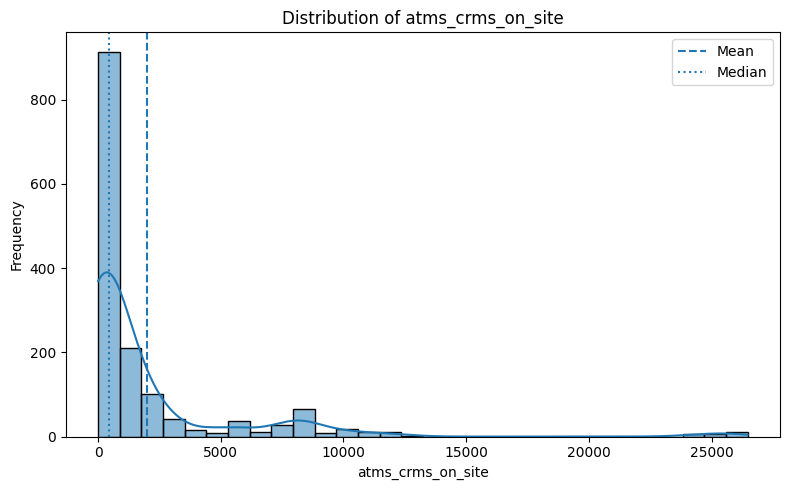

In [20]:
# Histogram - Mean vs Median
column = 'atms_crms_on_site'

plt.figure(figsize=(8, 5))
sns.histplot(df[column].dropna(), bins=30, kde=True)
plt.axvline(df[column].mean(), linestyle='--',
            label='Mean')
plt.axvline(df[column].median(), linestyle=':',
            label='Median')

plt.title(f'Distribution of {column}')
plt.xlabel(column)
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()


**Interpretation:**

1. The median is approximately 400, meaning around half of the observations have on-site ATM/CRM counts below this value and half above it.
2. The mean is approximately 1,900, which is much higher than the median.
3. Most observations are concentrated below approximately 2,000, while a few observations extend beyond 10,000.
4. Some observations reach approximately 26,000, contributing to the long right tail.
5. The difference between the mean and median indicates that the distribution is influenced by a small number of very high values. Hence, the distribution is highly right-skewed (positively skewed).


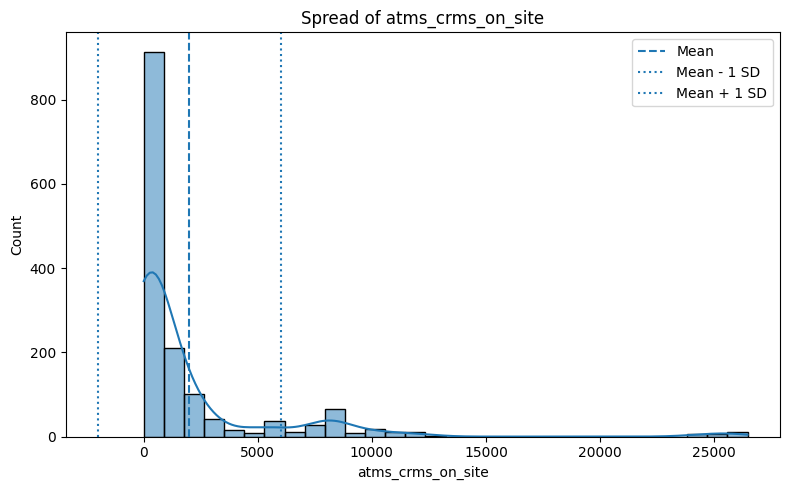

In [21]:
# Histogram - Standard Deviation
column = 'atms_crms_on_site'

plt.figure(figsize=(8, 5))
sns.histplot(df[column].dropna(), bins=30, kde=True)

mean_value = df[column].mean()
std_value = df[column].std()

plt.axvline(mean_value, linestyle='--', label='Mean')
plt.axvline(mean_value - std_value, linestyle=':',
            label='Mean - 1 SD')
plt.axvline(mean_value + std_value, linestyle=':',
            label='Mean + 1 SD')

plt.title(f'Spread of {column}')
plt.xlabel(column)
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:**

1. The mean on-site ATM/CRM count is approximately 1,900.



2. The standard deviation is approximately 3,700, indicating a wide spread of values around the mean.


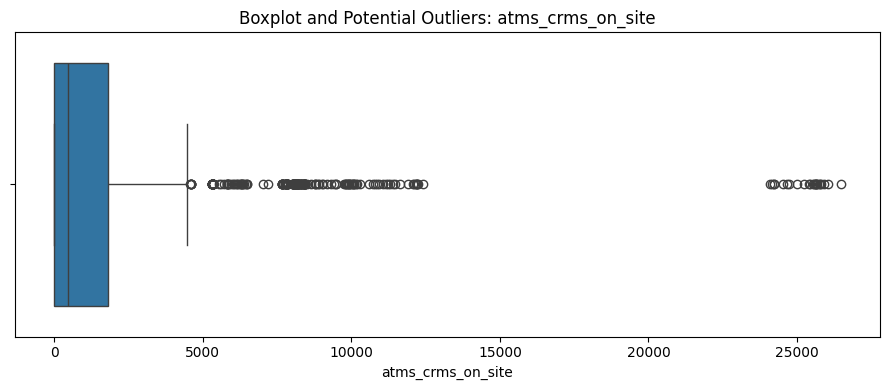

In [22]:
#Boxplot and Potential Outliers

column = 'atms_crms_on_site'

plt.figure(figsize=(9, 4))
sns.boxplot(x=df[column])

plt.title(f'Boxplot and Potential Outliers: {column}')
plt.xlabel(column)
plt.tight_layout()
plt.show()

**Interpretation:**  
**Median:** The line inside the box represents the median number of on-site ATMs/CRMs.



**Interquartile range (IQR):** The box represents the middle 50% of observations, between the 25th percentile (Q1) and the 75th percentile (Q3).



**Whiskers:** The whiskers show the range of values within the standard \(1.5 \times IQR\) outlier limits.



**Potential outliers:** The circles beyond the upper whisker represent observations with unusually high ATM/CRM counts. Some values are around 5,000–12,500, while another group lies around 24,000–26,500.

The boxplot of atms_crms_on_site reveals a **strongly right-skewed distribution** with several potential upper-end outliers. Most observations have relatively low on-site ATM/CRM counts, while a small number have substantially higher counts. These extreme values may reflect differences in banking infrastructure across banks rather than data-entry errors.

#**Bivariate Analysis**

Bivariate analysis was conducted to examine the relationship between on-site and off-site ATM/CRM infrastructure. A scatter plot and Pearson correlation coefficient were used to understand the direction and strength of the association between the two variables.

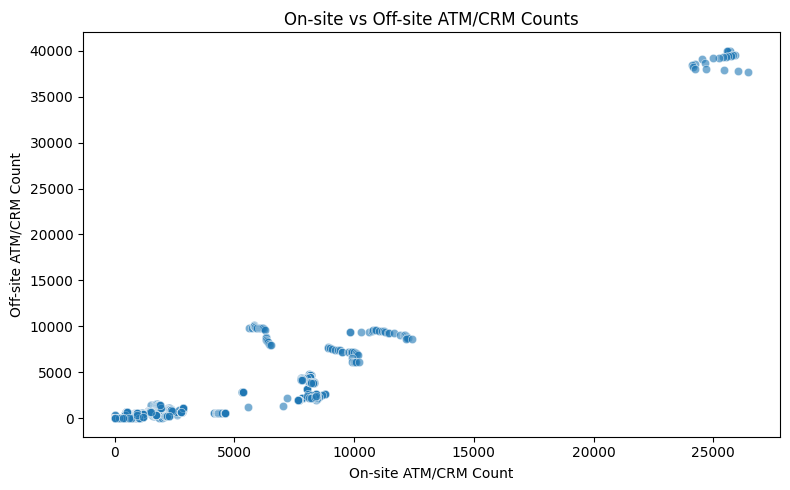

In [24]:
# Scatterplot — on-site vs. off-site ATM/CRM counts

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='atms_crms_on_site',
    y='atms_crms_off_site',
    alpha=0.6
)
plt.title('On-site vs Off-site ATM/CRM Counts')
plt.xlabel('On-site ATM/CRM Count')
plt.ylabel('Off-site ATM/CRM Count')
plt.tight_layout()
plt.show()

**Interpretation:**

1. The plot generally shows a positive relationship: observations with higher on-site counts tend to have higher off-site counts.

2. The observations are not evenly distributed. Several visible clusters appear, suggesting differences in infrastructure scale across banks or bank categories.

3. The upper-right cluster contains observations with approximately 24,000–26,000 on-site and 37,500–40,000 off-site ATM/CRM counts.

4. Some observations between approximately 5,000 and 7,000 on-site have off-site counts around 8,000–10,000, showing that off-site infrastructure can exceed on-site infrastructure.

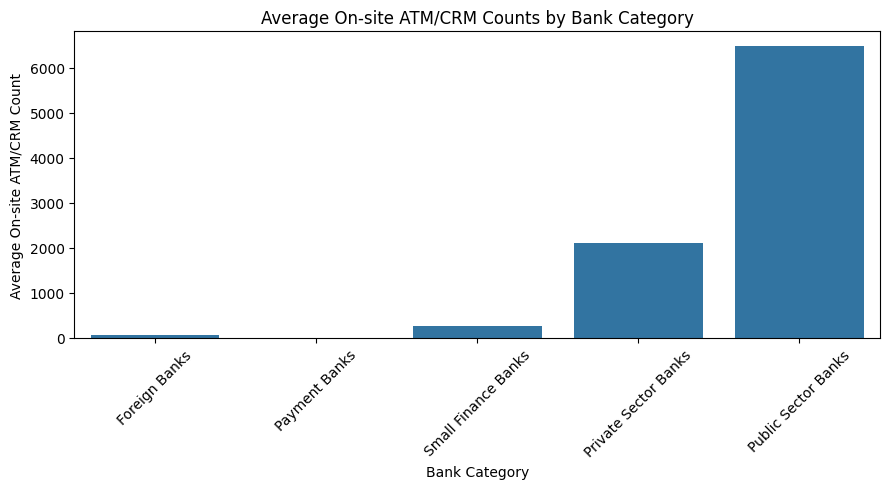

In [25]:
# Barplot — average on-site ATM/CRM counts by bank category

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x='bank_category',
    y='atms_crms_on_site',
    errorbar=None
)
plt.title('Average On-site ATM/CRM Counts by Bank Category')
plt.xlabel('Bank Category')
plt.ylabel('Average On-site ATM/CRM Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:**
1. Public Sector Banks recorded the highest average, at approximately 6,500 on-site ATM/CRM facilities.
2. Private Sector Banks ranked second, with an average of approximately 2,100.
3. Small Finance Banks had a much lower average of approximately 270.
4. Foreign Banks recorded approximately 70 on-site ATM/CRM facilities on average.
5. Payment Banks had an average close to zero, indicating very limited on-site ATM/CRM infrastructure in this dataset.

Public Sector Banks had an average approximately 3.1 times that of Private Sector Banks. Their average was also substantially higher than that of Small Finance Banks, Foreign Banks, and Payment Banks.

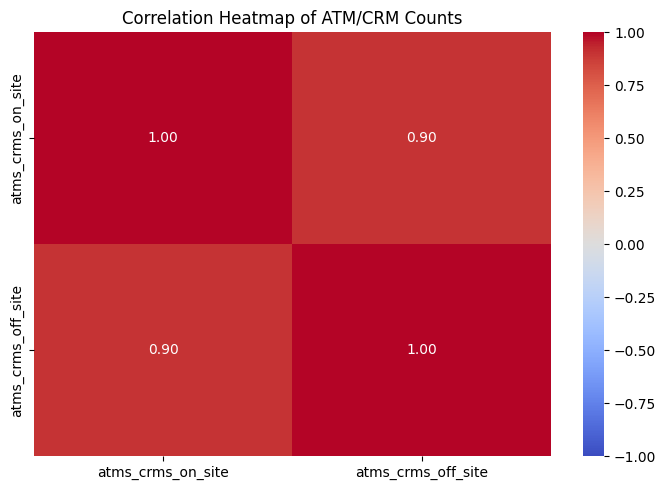

In [26]:
# Correlation heatmap — numerical variables

numeric_cols = [
    'atms_crms_on_site',
    'atms_crms_off_site'
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)
plt.title('Correlation Heatmap of ATM/CRM Counts')
plt.tight_layout()
plt.show()

**Interpretation:**

1. The correlation between on-site and off-site ATM/CRM counts is +0.90.
2. A correlation value of +0.90 is close to +1, indicating a strong positive linear relationship.
3. This means that observations with higher on-site ATM/CRM counts generally tend to have higher off-site ATM/CRM counts.
4. The diagonal values are 1.00 because each variable is perfectly correlated with itself.

#**Multi-variate Analysis**

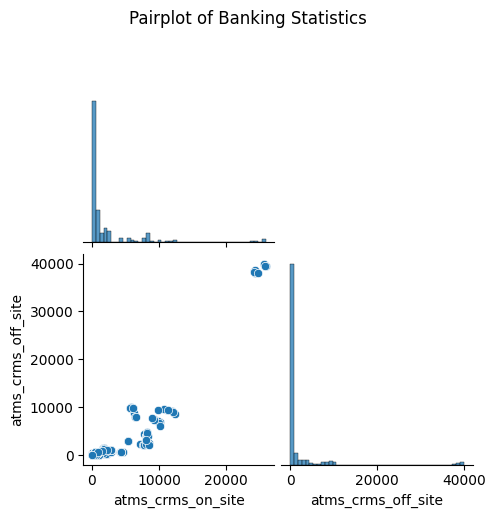

In [27]:
# Pairplot — relationships among numerical variables

pair_cols = [
    'atms_crms_on_site',
    'atms_crms_off_site'

]

sns.pairplot(
    df[pair_cols].dropna().sample(
        n=min(500, len(df[pair_cols].dropna())),
        random_state=42
    ),
    diag_kind='hist',
    corner=True
)
plt.suptitle('Pairplot of Banking Statistics', y=1.02)
plt.show()

**Interpretation:**

**Distribution**: Both variables are highly right-skewed. Most observations have relatively low counts, while a few observations have very high values.



**On-site ATM/CRM:** Most observations are concentrated below approximately 3,000, with a few reaching around 26,000.



**Off-site ATM/CRM:** Most observations are concentrated below approximately 1,500, while some reach approximately 40,000.



**Relationship:** The scatter plot shows a strong positive association. The correlation coefficient of approximately +0.90 indicates that higher on-site counts generally correspond to higher off-site counts.



**Clusters:** The plot contains distinct groups of observations, suggesting differences in infrastructure scale across banks or banking categories.

In [28]:
# Grouped analysis — bank category and reporting year

df['report_date'] = pd.to_datetime(df['report_date'], errors='coerce')

df['year'] = df['report_date'].dt.year

grouped_data = (
    df.groupby(['year', 'bank_category'])['atms_crms_on_site']
      .mean()
      .reset_index()
)

display(grouped_data)

,year,bank_category,atms_crms_on_site
0,2023,Foreign Banks,66.177419
1,2023,Payment Banks,0.166667
2,2023,Private Sector Banks,2028.547619
3,2023,Public Sector Banks,6522.847222
4,2023,Small Finance Banks,242.902778
5,2024,Foreign Banks,43.101190
6,2024,Payment Banks,0.027778
7,2024,Private Sector Banks,2198.095238
8,2024,Public Sector Banks,6454.444444
9,2024,Small Finance Banks,273.792593


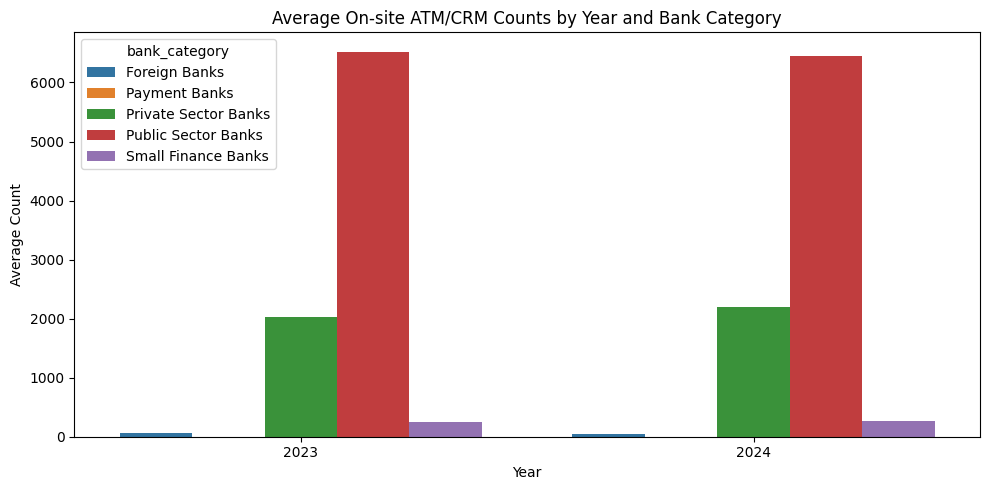

In [29]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=grouped_data,
    x='year',
    y='atms_crms_on_site',
    hue='bank_category',
    errorbar=None
)
plt.title('Average On-site ATM/CRM Counts by Year and Bank Category')
plt.xlabel('Year')
plt.ylabel('Average Count')
plt.tight_layout()
plt.show()

**Interpretation:**  

1. Public Sector Banks had the highest average on-site ATM/CRM infrastructure in both years. Their average decreased slightly from approximately 6,523 in 2023 to 6,454 in 2024, a decline of around 1.05%.

2. Private Sector Banks showed an increase from approximately 2,029 to 2,198, representing growth of around 8.36%.

3. Small Finance Banks increased from approximately 243 to 274, showing growth of around 12.71%.

4. Foreign Banks decreased from approximately 66 to 43, a decline of around 34.87%.

5. Payment Banks decreased from approximately 0.17 to 0.03. Although the percentage decline is large, the absolute infrastructure count was already very low.

In [30]:
# Pivot table — bank category, year, and ATM counts

pivot_table = pd.pivot_table(
    df,
    index='bank_category',
    columns='year',
    values='atms_crms_on_site',
    aggfunc='mean'
)

display(pivot_table.round(2))

year,2023,2024
bank_category,,
Foreign Banks,66.18,43.10
Payment Banks,0.17,0.03
Private Sector Banks,2028.55,2198.10
Public Sector Banks,6522.85,6454.44
Small Finance Banks,242.90,273.79


**Interpretation:**
1. Public Sector Banks: Recorded the highest average counts in both years, decreasing from 6,522.85 in 2023 to 6,454.44 in 2024. This represents a slight decline of approximately 1.05%.

2. Private Sector Banks: Increased from 2,028.55 to 2,198.10, a rise of approximately 8.36%, indicating an increase in average on-site ATM/CRM counts.

3. Small Finance Banks: Increased from 242.90 to 273.79, representing approximately 12.71% growth.

4. Foreign Banks: Decreased from 66.18 to 43.10, a decline of approximately 34.87%.

5. Payment Banks: Decreased from 0.17 to 0.03, showing a substantial percentage decline, although the absolute difference is very small.

# **Key Insights:**

1. Public Sector Banks have the largest ATM/CRM infrastructure.
They recorded the highest average counts in both years, decreasing slightly from 6,522.85 in 2023 to 6,454.44 in 2024. This indicates that public sector banks maintain a comparatively extensive physical banking network.

2. Private Sector Banks showed growth in on-site infrastructure.
The average on-site ATM/CRM count increased from approximately 2,029 in 2023 to 2,198 in 2024, representing growth of around 8.36%.

3. Small Finance Banks recorded infrastructure growth.
Their average on-site ATM/CRM count increased from approximately 243 in 2023 to 274 in 2024, a rise of around 12.71%.

4. On-site and off-site ATM/CRM counts have a strong positive relationship.
The correlation is approximately +0.90, suggesting that banks with more on-site ATMs/CRMs also tend to have more off-site ATMs/CRMs. This indicates an association, not causation.

5. Infrastructure is unevenly distributed across bank categories.
Public and private sector banks account for much higher average ATM/CRM counts than foreign and payment banks. Payment banks have very limited ATM/CRM infrastructure in comparison.

6. The findings can support digital banking recommendations.
Banks may use their existing ATM/CRM networks to improve customer awareness and access to digital services such as UPI, mobile banking, and internet banking.

**Descriptive Analysis:**

- Examined the mean, median, standard deviation, skewness, and kurtosis of numerical variables.
- Analysed the distribution of on-site and off-site ATM/CRM counts using histograms and boxplots.
- Compared average on-site ATM/CRM counts across bank categories.
- Used grouped analysis and pivot tables to compare 2023 and 2024.
- Observed that Public Sector Banks had the highest average on-site ATM/CRM counts in both years.

**Finding:** Banking infrastructure varies considerably across categories. Private Sector Banks and Small Finance Banks showed increases in average on-site ATM/CRM counts, while Public Sector Banks and Foreign Banks showed decreases.

**Diagnostic Analysis:**

- Used scatterplots to examine the relationship between on-site and off-site ATM/CRM counts.
- Applied correlation analysis to measure the strength of the relationship.
- Used boxplots to identify potential outliers.
- Compared infrastructure averages across bank categories and reporting years.

**Finding:** The strong positive correlation suggests that banks with larger on-site ATM/CRM networks generally tend to have larger off-site networks. Differences in bank category and infrastructure scale may contribute to the variation.

**Predictive Analysis:**

- Examined monthly ATM/CRM infrastructure trends.

- Compared historical monthly values across 2023 and 2024.

- Forecasting models can be proposed for selected ATM/CRM infrastructure measures.

**Expected Outcome:** Forecasting may provide an estimate of future ATM/CRM infrastructure trends and support preliminary infrastructure planning.

**Limitation:** The current analysis does not include validated forecasting results. Since the dataset covers only two years, predictions may be sensitive to short-term changes and should be interpreted cautiously.


**Prescriptive Analysis:**

- Identified bank categories showing increases or decreases in ATM/CRM infrastructure.

- Recommended evaluating infrastructure allocation alongside transaction activity and customer demand.

- Suggested examining UPI QR and POS adoption to identify potential opportunities for digital payment expansion, where relevant data is available.

- Recommended analysing credit- and debit-card transaction volumes and values to understand payment activity, where relevant data is available.

- Suggested considering demand, usage, operating costs, and geographic coverage when planning infrastructure.

**Expected Outcome:** The findings can support better-informed decisions regarding ATM/CRM infrastructure planning and the promotion of digital banking services.

**Limitation:** The current dataset alone cannot confirm where infrastructure expansion or reduction is necessary. Additional information on customer demand, transaction activity, operating costs, and geographic coverage would be required for stronger recommendations.

#**Final Conclusion:**

The analysis highlights significant differences in on-site ATM/CRM infrastructure across Indian bank categories during 2023–2024. Public Sector Banks maintained the highest average infrastructure counts, while Private Sector Banks and Small Finance Banks showed increases in their averages. A strong positive relationship was also observed between on-site and off-site ATM/CRM counts.

Based on these findings, I would recommend

**Public Sector Banks:** Use their extensive ATM/CRM networks to conduct digital payment awareness campaigns, especially for customers who may need assistance using UPI or mobile banking.



**Private Sector Banks:** Explore integrating digital banking promotions and QR-payment awareness into their existing ATM/CRM customer experience.



**Banks with smaller ATM/CRM networks:** Consider promoting digital-first services such as UPI and mobile banking to reduce dependence on physical banking infrastructure.


This would help banks identify opportunities to improve digital payment adoption while making better use of their existing banking infrastructure.

